# Figure 3: surface PV for increasing slope width and the flat-bottom control

Rows = output times, columns = experiments. All settings are in the configuration cell.

In [1]:
import warnings, glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import xarray as xr
from pathlib import Path
from dask.distributed import Client

warnings.filterwarnings('ignore')
print('Imports OK')

Imports OK


In [2]:
# Figure size matches a sidewaysfigure at width=0.9\textwidth (agujournal2019),
# so the font sizes below are the printed sizes.
LATEX_TEXT_WIDTH_IN = 9.38   # rotated text width (= portrait \textheight)
LATEX_WIDTH_FRAC    = 0.9    # use width=0.9\textwidth in the .tex
FIG_WIDTH_IN        = LATEX_TEXT_WIDTH_IN * LATEX_WIDTH_FRAC   # ≈ 8.4 in
FIG_HEIGHT_IN       = 4.9

ft_size    = 8
ft_small   = 7
plt.rcParams.update({
    'font.size':        ft_size,
    'axes.titlesize':   ft_size,
    'axes.labelsize':   ft_size,
    'xtick.labelsize':  ft_small,
    'ytick.labelsize':  ft_small,
    'legend.fontsize':  ft_size,
    'xtick.major.size': 2.5,
    'ytick.major.size': 2.5,
    'xtick.major.pad':  1.5,
    'ytick.major.pad':  1.5,
    'axes.linewidth':   0.6,
})

In [3]:
client = Client()
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/38905/status,
Dashboard: /proxy/38905/status,Workers: 7
Total threads: 28,Total memory: 125.19 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:36947,Workers: 0
Dashboard: /proxy/38905/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:41411,Total threads: 4
Dashboard: /proxy/43161/status,Memory: 17.88 GiB
Nanny: tcp://127.0.0.1:34183,


## Configuration

In [4]:
from pathlib import Path

# Archive roots, searched in order
ARCHIVE_ROOTS = [
    Path('/scratch/nm03/ae7501/mom6/archive'),
    Path('/g/data/nm03/ae7501/mom6_outputs/from_scratch/idealized'),
]

# Depth level
ZL_INDEX   = 0        # 0 = surface layer
F_CORIOLIS = -1e-5    # s^-1  (Southern Hemisphere f-plane)

# Output time indices to plot (hourly output)
PLOT_TIMESTEPS = [300, 450, 500, 600]

# y-axis crop (km)
Y_MIN, Y_MAX = 170, 230

# Colour scale (negative PV only)
PV_VMIN = -2e-7   # set to None for auto (2nd percentile across all experiments)

# Output directory
OUT_DIR = Path('pv_plots')
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Experiments, one per column. L_jet = 5 km, U0 = 0.2 m/s, |f0| = 1e-5 s^-1:
# Ro = 4, h_hat = 0.2, X_j = 0 in every sloping case; W_hat = W_s / L_jet.
EXPERIMENT_CONFIGS = [
    dict(label=r'$\hat{W} = 1$',   experiment='test160'),   # W_s =  5 km
    dict(label=r'$\hat{W} = 5$',   experiment='test162'),   # W_s = 25 km
    dict(label=r'$\hat{W} = 9$',   experiment='test164'),   # W_s = 45 km
    dict(label=r'$\hat{W} = 13$',  experiment='test166'),   # W_s = 65 km
    dict(label=r'$\hat{W} = 17$',  experiment='test168'),   # W_s = 85 km
    dict(label='Flat bottom',       experiment='test242'),   # h_s = 1
]

print(f'{len(EXPERIMENT_CONFIGS)} experiment(s) configured.')
print(f'Timesteps : {PLOT_TIMESTEPS}')
print(f'y-crop    : {Y_MIN}–{Y_MAX} km')

6 experiment(s) configured.
Timesteps : [300, 450, 500, 600]
y-crop    : 170–230 km


## Load all experiments

In [5]:
def find_exp_dir(experiment, roots):
    """Search each root in order; return the first matching directory."""
    for root in roots:
        matches = sorted(root.glob(f"{experiment}-*"))
        if matches:
            return matches[0]
    return None

def scale_to_strip(vals, x0, x1, strip_frac=0.15, left_offset_frac=0.02):
    """Normalise vals into a narrow x-strip for profile overlays."""
    vmin, vmax = np.nanmin(vals), np.nanmax(vals)
    if vmax > vmin:
        return (vals - vmin) / (vmax - vmin) * (x1 - x0) * strip_frac                + x0 + (x1 - x0) * left_offset_frac
    return np.full_like(vals, x0 + (x1 - x0) * left_offset_frac)

EXPERIMENTS = []

for cfg in EXPERIMENT_CONFIGS:
    exp_name = cfg['experiment']
    label    = cfg['label']

    exp_dir = find_exp_dir(exp_name, ARCHIVE_ROOTS)
    if exp_dir is None:
        print(f'[SKIP] {exp_name} — not found in any archive root')
        continue
    print(f'[FOUND] {exp_name} → {exp_dir}')

    output_dir  = exp_dir / 'output000'
    static_file = output_dir / 'ocean_static.nc'
    ic_file     = output_dir / 'MOM_IC.nc'

    for f in [static_file, ic_file]:
        if not f.exists():
            print(f'  [WARN] missing: {f}')

    # Static / bathymetry
    ds_static  = xr.open_dataset(static_file).drop_vars(['time'], errors='ignore')
    deptho     = ds_static['deptho']                     # (yh, xh), metres down
    depth_vals = deptho.values
    bathy_xh   = deptho.xh.values / 1e3
    bathy_yh   = deptho.yh.values / 1e3
    bmin       = float(np.nanmin(depth_vals[depth_vals > 0]))
    bmax       = float(np.nanmax(depth_vals))
    bathy_lvl  = np.array([0.5 * (bmin + bmax)])        # mid-slope isobath

    # Initial conditions
    ds_ic  = xr.open_dataset(ic_file)
    u_ic   = ds_ic['u']
    if 'Time' in u_ic.dims:
        u_ic = u_ic.isel(Time=0)
    ic_y = 'lath' if 'lath' in u_ic.dims else 'yh'
    ic_x = 'lonq' if 'lonq' in u_ic.dims else 'xh'

    u_ic_zmean = u_ic.isel(Layer=ZL_INDEX).mean(dim=ic_x).squeeze()
    yh_ic_km   = ds_ic[ic_y].values / 1e3

    # Initial PV profile: (f + zeta) / h
    deptho_zmean = deptho.mean(dim='xh').values
    h_on_ic_y    = np.interp(ds_ic[ic_y].values, deptho.yh.values, deptho_zmean)
    u_vals       = u_ic_zmean.values.squeeze()
    zeta_ic      = -np.gradient(u_vals, ds_ic[ic_y].values)
    pv_ic        = (F_CORIOLIS + zeta_ic) / h_on_ic_y

    # PV field
    interior_files = sorted(glob.glob(str(exp_dir / 'output*' / 'ocean_interior.nc')))
    if not interior_files:
        print(f'  [SKIP] no ocean_interior.nc under {exp_dir}')
        continue

    ds_int  = xr.open_mfdataset(interior_files, combine='by_coords')
    pv_full = ds_int['PV']
    n_times = len(pv_full.time)

    valid_t = [t for t in PLOT_TIMESTEPS if t < n_times]
    skipped = [t for t in PLOT_TIMESTEPS if t >= n_times]
    if skipped:
        print(f'  [WARN] timesteps {skipped} exceed length {n_times} — skipped')
    if not valid_t:
        print(f'  [SKIP] no valid timesteps for {exp_name}')
        continue

    pv_sel = (pv_full.isel(time=valid_t, zl=ZL_INDEX)
              if 'zl' in pv_full.dims
              else pv_full.isel(time=valid_t)).compute()

    # Grid
    xh_km = pv_sel.xh.values / 1e3 if 'xh' in pv_sel.coords else pv_sel.xq.values / 1e3
    yh_km = pv_sel.yh.values / 1e3 if 'yh' in pv_sel.coords else pv_sel.yq.values / 1e3
    x0, x1 = float(xh_km.min()), float(xh_km.max())

    # Scale profile lines
    u_sc   = scale_to_strip(u_vals, x0, x1)
    pv0_sc = scale_to_strip(pv_ic.squeeze(), x0, x1)

    # Topography: right-aligned strip
    topo_zmean = deptho.mean(dim='xh').values
    topo_yh    = deptho.yh.values / 1e3
    topo_raw   = scale_to_strip(topo_zmean, x0, x1)
    topo_sc    = topo_raw - topo_raw.min() + (x1 - (x1 - x0) * 0.17)

    EXPERIMENTS.append(dict(
        label      = label,
        pv         = pv_sel,
        valid_t    = valid_t,
        xh_km      = xh_km,
        yh_km      = yh_km,
        x0=x0, x1=x1,
        bathy_xh   = bathy_xh,
        bathy_yh   = bathy_yh,
        depth_vals = depth_vals,
        bathy_lvl  = bathy_lvl,
        u_sc       = u_sc,
        yh_ic      = yh_ic_km,
        pv0_sc     = pv0_sc,
        topo_sc    = topo_sc,
        topo_yh    = topo_yh,
    ))
    print(f'  PV shape: {pv_sel.shape},  '
          f'PV range: {float(pv_sel.min()):.3e} – {float(pv_sel.max()):.3e}')

print(f'\n{len(EXPERIMENTS)} experiment(s) loaded successfully.')

[FOUND] test160 → /g/data/nm03/ae7501/mom6_outputs/from_scratch/idealized/test160-8f02e65f


2026-10-08 19:00:29,892 - distributed.worker.memory - WARNING - Unmanaged memory use is high. This may indicate a memory leak or the memory may not be released to the OS; see https://distributed.dask.org/en/latest/worker-memory.html#memory-not-released-back-to-the-os for more information. -- Unmanaged memory: 12.59 GiB -- Worker memory limit: 17.88 GiB


  PV shape: (4, 1334, 1667),  PV range: -6.391e-07 – -2.000e-08
[FOUND] test162 → /g/data/nm03/ae7501/mom6_outputs/from_scratch/idealized/test162-26d1ea04
  PV shape: (4, 1334, 1667),  PV range: -1.853e-07 – -2.000e-08
[FOUND] test164 → /g/data/nm03/ae7501/mom6_outputs/from_scratch/idealized/test164-04bbe67e
  PV shape: (4, 1334, 1667),  PV range: -1.544e-07 – -2.000e-08
[FOUND] test166 → /g/data/nm03/ae7501/mom6_outputs/from_scratch/idealized/test166-fa1ce574


2026-10-08 19:05:40,594 - distributed.worker.memory - WARNING - Unmanaged memory use is high. This may indicate a memory leak or the memory may not be released to the OS; see https://distributed.dask.org/en/latest/worker-memory.html#memory-not-released-back-to-the-os for more information. -- Unmanaged memory: 12.65 GiB -- Worker memory limit: 17.88 GiB


  PV shape: (4, 1334, 1667),  PV range: -1.512e-07 – -2.000e-08
[FOUND] test168 → /g/data/nm03/ae7501/mom6_outputs/from_scratch/idealized/test168-fcb04f4a
  PV shape: (4, 1334, 1667),  PV range: -1.503e-07 – -2.000e-08
[FOUND] test242 → /g/data/nm03/ae7501/mom6_outputs/from_scratch/idealized/test242-56c779dd


2026-10-08 19:07:10,402 - distributed.worker.memory - WARNING - Unmanaged memory use is high. This may indicate a memory leak or the memory may not be released to the OS; see https://distributed.dask.org/en/latest/worker-memory.html#memory-not-released-back-to-the-os for more information. -- Unmanaged memory: 12.68 GiB -- Worker memory limit: 17.88 GiB


  PV shape: (4, 1334, 1667),  PV range: -8.966e-08 – -2.000e-08

6 experiment(s) loaded successfully.


## Multi-experiment panel plot

Colour scale: -2.000e-07 → 0.0


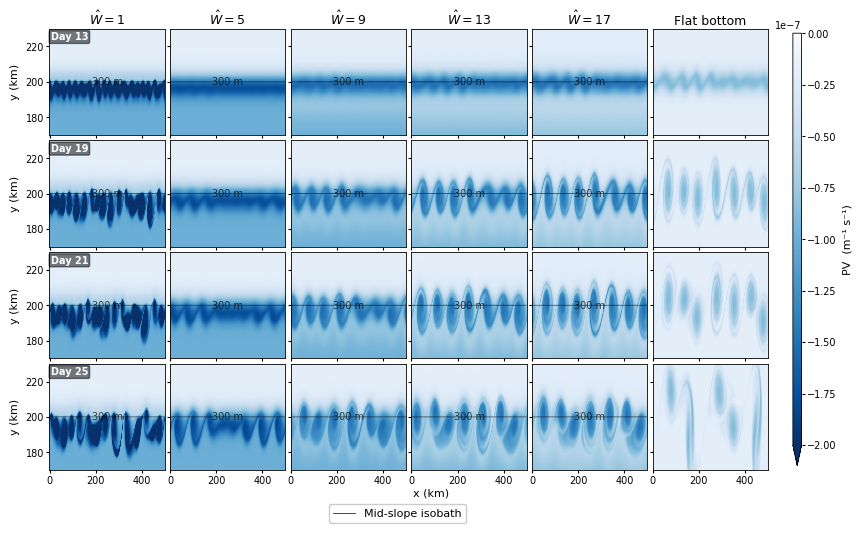

Saved → pv_plots/pv_multiexp_t300_450_500_600.png


In [6]:
if not EXPERIMENTS:
    raise RuntimeError('EXPERIMENTS list is empty — check loading cell above.')

ncols = len(EXPERIMENTS)
nrows = len(PLOT_TIMESTEPS)

# Global colour scale (negative values only)
if PV_VMIN is not None:
    pv_vmin = PV_VMIN
else:
    pv_vmin = float(np.nanpercentile(
        np.concatenate([e['pv'].values.ravel() for e in EXPERIMENTS]), 2
    ))
pv_vmax = 0.0
print(f'Colour scale: {pv_vmin:.3e} → {pv_vmax}')

# Figure
fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(FIG_WIDTH_IN, FIG_HEIGHT_IN),
    sharex='col', sharey=True,
    layout='constrained',
)
fig.get_layout_engine().set(w_pad=0.01, h_pad=0.01, hspace=0.0, wspace=0.0)

if nrows == 1: axes = axes[np.newaxis, :]
if ncols == 1: axes = axes[:, np.newaxis]

im_ref = None

for col, exp in enumerate(EXPERIMENTS):
    pv_data = exp['pv']
    xh      = exp['xh_km']
    yh      = exp['yh_km']
    x0, x1  = exp['x0'], exp['x1']

    for row, t_idx in enumerate(PLOT_TIMESTEPS):
        ax = axes[row, col]

        if t_idx not in exp['valid_t']:
            ax.set_visible(False)
            continue
        local_idx = exp['valid_t'].index(t_idx)

        pv_snap    = pv_data.isel(time=local_idx).values
        time_label = str(pv_data.time.values[local_idx])[:10]

        # PV field
        im = ax.pcolormesh(
            xh, yh, pv_snap,
            cmap='Blues_r', vmin=pv_vmin, vmax=pv_vmax,
            shading='auto', rasterized=True,
        )
        im_ref = im

        # Bathymetry contour
        cs = ax.contour(
            exp['bathy_xh'], exp['bathy_yh'], exp['depth_vals'],
            levels=exp['bathy_lvl'],
            colors='k', linewidths=0.5, alpha=0.7,
        )
        all_paths = cs.get_paths()
        if all_paths:
            verts = np.concatenate([p.vertices for p in all_paths], axis=0)
            mask  = (verts[:, 1] >= Y_MIN) & (verts[:, 1] <= Y_MAX)
            vis   = verts[mask]
            if vis.size > 0:
                try:
                    lbls = ax.clabel(cs, fmt='%.0f m', fontsize=ft_small,
                                     inline=False,
                                     manual=[(vis[:, 0].mean(), vis[:, 1].mean())])
                    for l in lbls:
                        l.set_clip_on(True)
                except (TypeError, IndexError):
                    ax.clabel(cs, fmt='%.0f m', fontsize=ft_small, inline=True)

        # Days since model start (0001-01-01)
        t_val  = pv_data.time.values[local_idx]
        t_days = (t_val - type(t_val)(1, 1, 1)).total_seconds() / 86400
        # Time label, left column only
        if col == 0:
            ax.text(
                0.01, 0.97, f'Day {t_days:.0f}',
                transform=ax.transAxes,
                fontsize=ft_small, fontweight='bold', va='top', ha='left',
                color='white',
                bbox=dict(boxstyle='round,pad=0.15', facecolor='black', alpha=0.5),
            )

        ax.set_ylim(Y_MIN, Y_MAX)

        # Axis labels
        ax.set_ylabel('y (km)' if col == 0 else '', fontsize=ft_size)
        ax.xaxis.set_major_locator(plt.MaxNLocator(3))
        if row < nrows - 1:
            ax.tick_params(labelbottom=False)
            ax.set_xlabel('')
        else:
            ax.set_xlabel('')

    # Column title
    axes[0, col].set_title(exp['label'], fontsize=ft_size + 1, pad=3)

fig.supxlabel('x (km)', fontsize=ft_size)

# Shared colorbar
cbar = fig.colorbar(
    im_ref, ax=axes,
    label='PV  (m⁻¹ s⁻¹)',
    pad=0.01, aspect=50, shrink=0.98,
    extend='min',
)
cbar.ax.tick_params(labelsize=ft_small)
cbar.set_label('PV  (m⁻¹ s⁻¹)', fontsize=ft_size)

# Common legend at bottom
legend_handles = [
    mlines.Line2D([], [], color='k',           lw=0.5, ls='-',  label='Mid-slope isobath'),
]
fig.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.46, 0.0),
    ncol=1, fontsize=ft_size, frameon=True,
    title='', title_fontsize=ft_size,
    framealpha=1,
)

# Save
fname = f'pv_multiexp_t{"_".join(str(t) for t in PLOT_TIMESTEPS)}.png'
plt.savefig(OUT_DIR / fname, dpi=300, bbox_inches='tight', pad_inches=0.02)
plt.show()
print(f'Saved → {OUT_DIR / fname}')